In [3]:
import pandas as pd

df = pd.read_csv("../data/Telco-Customer-Churn.csv")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.shape

(7043, 21)

In [5]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [5]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [9]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

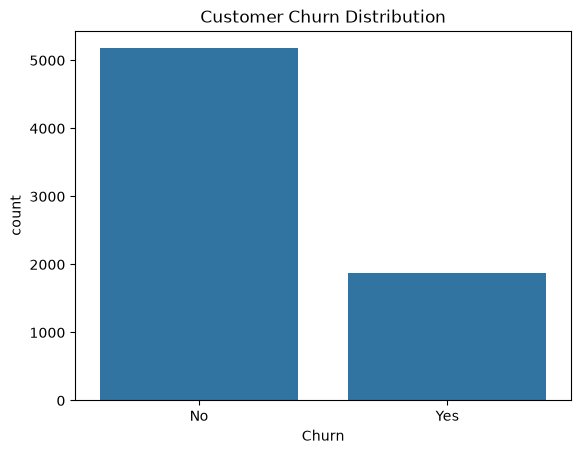

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.show()

In [11]:
df_clean = df.copy()

In [12]:
df_clean = df_clean.drop("customerID", axis=1)

In [13]:
df_clean.shape

(7043, 20)

In [14]:
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"],
    errors="coerce"
)

In [15]:
df_clean.isnull().sum()

gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [16]:
df_clean[df_clean["TotalCharges"].isnull()][
    ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,NaN,No
753,0,20.25,NaN,No
936,0,80.85,NaN,No
1082,0,25.75,NaN,No
1340,0,56.05,NaN,No
3331,0,19.85,NaN,No
3826,0,25.35,NaN,No
4380,0,20.00,NaN,No
5218,0,19.70,NaN,No
6670,0,73.35,NaN,No


In [17]:
df_clean["TotalCharges"] = df_clean["TotalCharges"].fillna(0)

In [18]:
df_clean.isnull().sum()

gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [19]:
df_clean.duplicated().sum()

np.int64(22)

In [20]:
df_clean["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [21]:
df_clean["Churn"].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

In [22]:
df_clean["Churn"] = df_clean["Churn"].map({
    "No": 0,
    "Yes": 1
})

In [23]:
df_clean["Churn"].value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

In [24]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 non-null   str    
 14  Contract          7043 non-null   str    
 15  PaperlessBilling  7043 non-null   str    
 16  PaymentMethod     7043 non-null   str    
 17  Monthl

In [25]:
df_clean.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


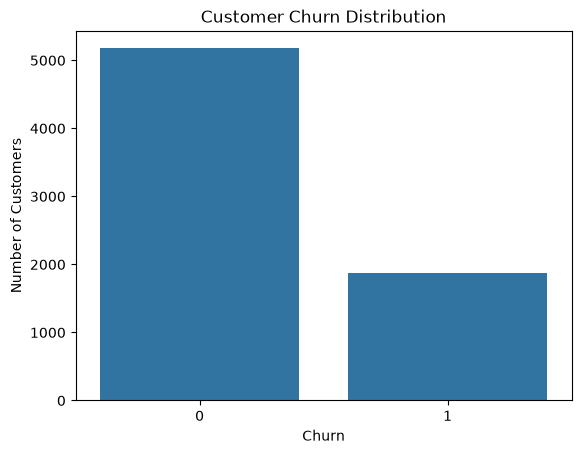

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df_clean, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

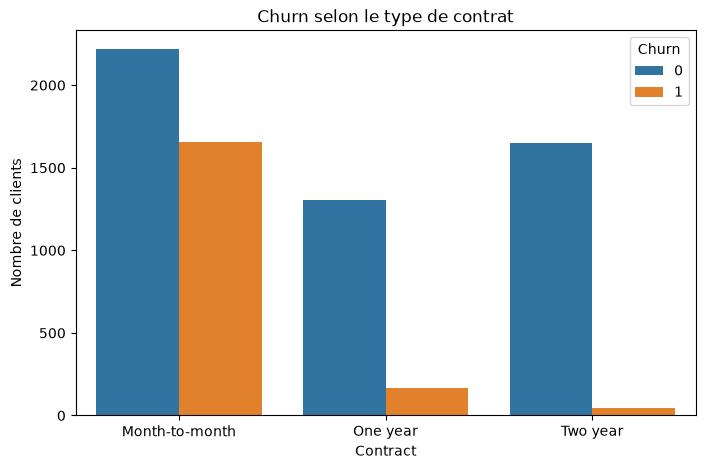

In [27]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="Contract",
    hue="Churn"
)

plt.title("Churn selon le type de contrat")
plt.xlabel("Contract")
plt.ylabel("Nombre de clients")
plt.show()

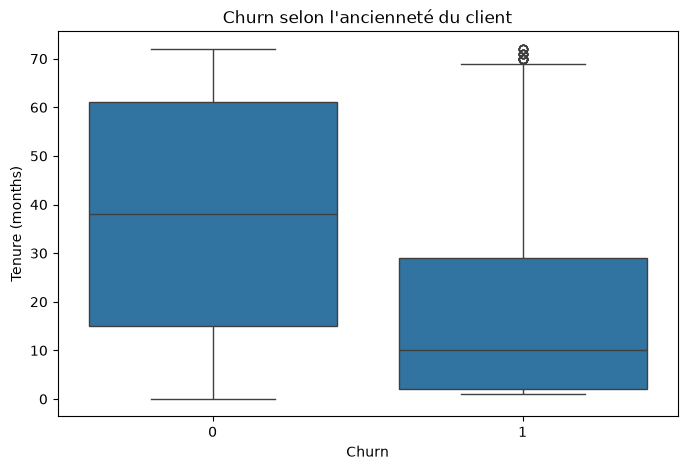

In [28]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="Churn",
    y="tenure"
)

plt.title("Churn selon l'ancienneté du client")
plt.xlabel("Churn")
plt.ylabel("Tenure (months)")
plt.show()

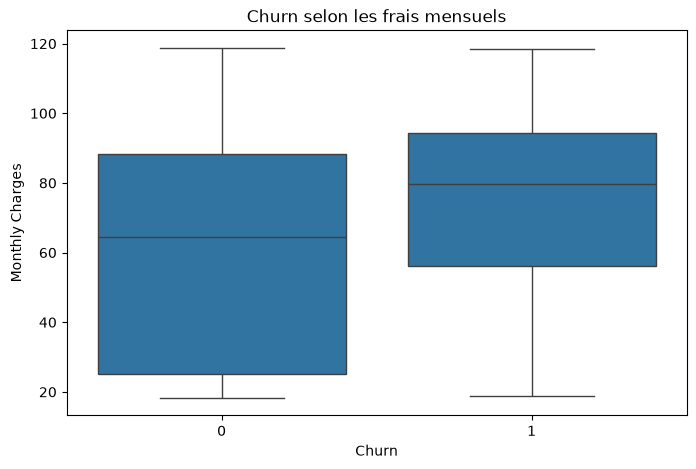

In [29]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Churn selon les frais mensuels")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.show()

In [30]:
df_clean.groupby("Churn")[[
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]].mean()

,tenure,MonthlyCharges,TotalCharges
Churn,,,
0,37.569965,61.265124,2549.911442
1,17.979133,74.441332,1531.796094


In [31]:
df_clean["Churn"].value_counts(normalize=True) * 100

Churn
0    73.463013
1    26.536987
Name: proportion, dtype: float64

In [32]:
df_clean.groupby("Churn")[[
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]].mean()

,tenure,MonthlyCharges,TotalCharges
Churn,,,
0,37.569965,61.265124,2549.911442
1,17.979133,74.441332,1531.796094


In [33]:
X = df_clean.drop("Churn", axis=1)
y = df_clean["Churn"]

In [34]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (7043, 19)
y shape: (7043,)


In [35]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["str"]
).columns.tolist()

print("Variables numériques :")
print(numeric_features)

print("\nVariables catégorielles :")
print(categorical_features)

Variables numériques :
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Variables catégorielles :
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [36]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [37]:
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (5634, 19)
X_test : (1409, 19)
y_train: (5634,)
y_test : (1409,)


In [38]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

In [39]:
numeric_transformer = StandardScaler()

In [40]:
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

In [41]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [42]:
print(preprocessor)

ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['SeniorCitizen', 'tenure', 'MonthlyCharges',
                                  'TotalCharges']),
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['gender', 'Partner', 'Dependents',
                                  'PhoneService', 'MultipleLines',
                                  'InternetService', 'OnlineSecurity',
                                  'OnlineBackup', 'DeviceProtection',
                                  'TechSupport', 'StreamingTV',
                                  'StreamingMovies', 'Contract',
                                  'PaperlessBilling', 'PaymentMethod'])])


In [43]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

In [44]:
logistic_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(max_iter=1000))
    ]
)

In [43]:
logistic_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pa

In [44]:
y_pred = logistic_pipeline.predict(X_test)

In [45]:
print(y_pred[:20])

[0 1 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 1 0 0]


In [46]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.8055358410220014


In [47]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



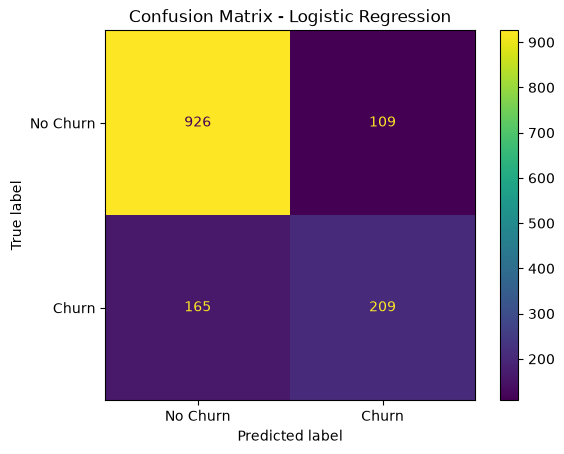

In [48]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot()
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

In [49]:
from sklearn.ensemble import RandomForestClassifier

In [50]:
rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

In [51]:
rf_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pa

In [52]:
y_pred_rf = rf_pipeline.predict(X_test)

In [53]:
print("Accuracy:", accuracy_score(y_test, y_pred_rf))

print(
    classification_report(
        y_test,
        y_pred_rf
    )
)

Accuracy: 0.7835344215755855
              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1035
           1       0.62      0.48      0.54       374

    accuracy                           0.78      1409
   macro avg       0.72      0.69      0.70      1409
weighted avg       0.77      0.78      0.77      1409



In [54]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [55]:
from xgboost import XGBClassifier

In [56]:
xgb_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", XGBClassifier(
            n_estimators=200,
            max_depth=5,
            learning_rate=0.05,
            random_state=42,
            eval_metric="logloss"
        ))
    ]
)

In [57]:
xgb_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pa

In [58]:
y_pred_xgb = xgb_pipeline.predict(X_test)

In [59]:
print("Accuracy:", accuracy_score(y_test, y_pred_xgb))

print(classification_report(
    y_test,
    y_pred_xgb
))

Accuracy: 0.794889992902768
              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1035
           1       0.64      0.51      0.57       374

    accuracy                           0.79      1409
   macro avg       0.74      0.70      0.72      1409
weighted avg       0.78      0.79      0.79      1409



In [61]:
%pip install mlflow

  Using cached mlflow-3.16.1-py3-none-any.whl.metadata (50 kB)
  Using cached mlflow_skinny-3.16.1-py3-none-any.whl.metadata (50 kB)
  Using cached mlflow_tracing-3.16.1-py3-none-any.whl.metadata (19 kB)
  Using cached flask_cors-6.0.5-py3-none-any.whl.metadata (5.4 kB)
  Using cached flask-3.1.3-py3-none-any.whl.metadata (3.2 kB)
  Using cached aiohttp-3.14.3-cp313-cp313-win_amd64.whl.metadata (8.5 kB)
  Using cached alembic-1.20.0-py3-none-any.whl.metadata (7.3 kB)
  Using cached docker-7.2.0-py3-none-any.whl.metadata (3.8 kB)
  Using cached graphene-3.4.3-py2.py3-none-any.whl.metadata (6.9 kB)
  Using cached huey-3.4.0-py3-none-any.whl.metadata (5.7 kB)
  Using cached skops-0.16.0-py3-none-any.whl.metadata (4.3 kB)
  Using cached sqlalchemy-2.1.1-cp313-cp313-win_amd64.whl.metadata (9.9 kB)
  Using cached waitress-3.0.2-py3-none-any.whl.metadata (5.8 kB)
  Using cached databricks_sdk-0.143.0-py3-none-any.whl.metadata (44 kB)
  Using cached importlib_metadata-9.0.1-py3-none-any.whl.me


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [62]:
import mlflow

In [63]:
mlflow.set_experiment("Telco Customer Churn")

2026/09/27 16:11:44 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/09/27 16:11:44 INFO mlflow.store.db.utils: Updating database tables
2026/09/27 16:11:48 INFO mlflow.tracking.fluent: Experiment with name 'Telco Customer Churn' does not exist. Creating a new experiment.


<Experiment: artifact_location='file:C:/Users/DELL/Desktop/PFE_2027/telco-churn-mlops/notebooks/mlruns/1', creation_time=1790521908239, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1790521908239, lifecycle_stage='active', name='Telco Customer Churn', tags={}, trace_location=None, workspace='default'>

In [64]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

with mlflow.start_run(run_name="Logistic Regression"):

    # Entraînement
    logistic_pipeline.fit(X_train, y_train)

    # Prédiction
    y_pred = logistic_pipeline.predict(X_test)

    # Métriques
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    # Enregistrer les paramètres
    mlflow.log_param("model", "Logistic Regression")
    mlflow.log_param("max_iter", 1000)

    # Enregistrer les métriques
    mlflow.log_metric("accuracy", accuracy)
    mlflow.log_metric("precision", precision)
    mlflow.log_metric("recall", recall)
    mlflow.log_metric("f1_score", f1)

    print("Accuracy:", accuracy)
    print("Precision:", precision)
    print("Recall:", recall)
    print("F1:", f1)

Accuracy: 0.8055358410220014
Precision: 0.6572327044025157
Recall: 0.5588235294117647
F1: 0.6040462427745664


In [65]:
with mlflow.start_run(run_name="Random Forest"):

    # Entraînement
    rf_pipeline.fit(X_train, y_train)

    # Prédiction
    y_pred_rf = rf_pipeline.predict(X_test)

    # Métriques
    accuracy_rf = accuracy_score(y_test, y_pred_rf)
    precision_rf = precision_score(y_test, y_pred_rf)
    recall_rf = recall_score(y_test, y_pred_rf)
    f1_rf = f1_score(y_test, y_pred_rf)

    # Paramètres
    mlflow.log_param("model", "Random Forest")
    mlflow.log_param("n_estimators", 200)
    mlflow.log_param("random_state", 42)

    # Métriques
    mlflow.log_metric("accuracy", accuracy_rf)
    mlflow.log_metric("precision", precision_rf)
    mlflow.log_metric("recall", recall_rf)
    mlflow.log_metric("f1_score", f1_rf)

    print("Accuracy:", accuracy_rf)
    print("Precision:", precision_rf)
    print("Recall:", recall_rf)
    print("F1:", f1_rf)

Accuracy: 0.7835344215755855
Precision: 0.6185567010309279
Recall: 0.48128342245989303
F1: 0.5413533834586466


In [66]:
with mlflow.start_run(run_name="XGBoost"):

    # Entraînement
    xgb_pipeline.fit(X_train, y_train)

    # Prédiction
    y_pred_xgb = xgb_pipeline.predict(X_test)

    # Métriques
    accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
    precision_xgb = precision_score(y_test, y_pred_xgb)
    recall_xgb = recall_score(y_test, y_pred_xgb)
    f1_xgb = f1_score(y_test, y_pred_xgb)

    # Paramètres
    mlflow.log_param("model", "XGBoost")
    mlflow.log_param("n_estimators", 200)
    mlflow.log_param("max_depth", 5)
    mlflow.log_param("learning_rate", 0.05)
    mlflow.log_param("random_state", 42)

    # Métriques
    mlflow.log_metric("accuracy", accuracy_xgb)
    mlflow.log_metric("precision", precision_xgb)
    mlflow.log_metric("recall", recall_xgb)
    mlflow.log_metric("f1_score", f1_xgb)

    print("Accuracy:", accuracy_xgb)
    print("Precision:", precision_xgb)
    print("Recall:", recall_xgb)
    print("F1:", f1_xgb)

Accuracy: 0.794889992902768
Precision: 0.6430976430976431
Recall: 0.5106951871657754
F1: 0.5692995529061102


In [67]:
import mlflow.sklearn

In [68]:
with mlflow.start_run(run_name="Logistic Regression - Model"):

    logistic_pipeline.fit(X_train, y_train)

    y_pred = logistic_pipeline.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    mlflow.log_metric("accuracy", accuracy)
    mlflow.log_metric("precision", precision)
    mlflow.log_metric("recall", recall)
    mlflow.log_metric("f1_score", f1)

    mlflow.sklearn.log_model(
        logistic_pipeline,
        "model"
    )

2026/09/27 16:28:48 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


In [71]:
with mlflow.start_run(run_name="Random Forest - Model"):

    rf_pipeline.fit(X_train, y_train)

    y_pred_rf = rf_pipeline.predict(X_test)

    accuracy_rf = accuracy_score(y_test, y_pred_rf)
    precision_rf = precision_score(y_test, y_pred_rf)
    recall_rf = recall_score(y_test, y_pred_rf)
    f1_rf = f1_score(y_test, y_pred_rf)

    mlflow.log_metric("accuracy", accuracy_rf)
    mlflow.log_metric("precision", precision_rf)
    mlflow.log_metric("recall", recall_rf)
    mlflow.log_metric("f1_score", f1_rf)

    mlflow.sklearn.log_model(
        sk_model=rf_pipeline,
        name="model",
        serialization_format="cloudpickle"
    )

2026/09/27 16:33:51 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


In [72]:
with mlflow.start_run(run_name="XGBoost - Model"):

    xgb_pipeline.fit(X_train, y_train)

    y_pred_xgb = xgb_pipeline.predict(X_test)

    accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
    precision_xgb = precision_score(y_test, y_pred_xgb)
    recall_xgb = recall_score(y_test, y_pred_xgb)
    f1_xgb = f1_score(y_test, y_pred_xgb)

    mlflow.log_metric("accuracy", accuracy_xgb)
    mlflow.log_metric("precision", precision_xgb)
    mlflow.log_metric("recall", recall_xgb)
    mlflow.log_metric("f1_score", f1_xgb)

    mlflow.sklearn.log_model(
        sk_model=xgb_pipeline,
        name="model",
        serialization_format="cloudpickle"
    )

2026/09/27 16:33:59 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


In [73]:
%pip install fastapi uvicorn mlflow scikit-learn pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
%pip install scikit-learn==1.9.1

  Using cached scikit_learn-1.9.1-cp313-cp313-win_amd64.whl.metadata (9.3 kB)
Using cached scikit_learn-1.9.1-cp313-cp313-win_amd64.whl (8.2 MB)
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.7.2
    Uninstalling scikit-learn-1.7.2:
      Successfully uninstalled scikit-learn-1.7.2
Note: you may need to restart the kernel to use updated packages.


  You can safely remove it manually.

[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [45]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import mlflow

# 1. Définir la recherche d'hyperparamètres
lr_search = RandomizedSearchCV(
    estimator=logistic_pipeline,
    param_distributions={
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__class_weight": [None, "balanced"]
    },
    n_iter=8,
    scoring="f1",
    cv=3,
    random_state=42,
    n_jobs=1,
    verbose=1
)

# 2. Optimiser sur les données d'entraînement uniquement
lr_search.fit(X_train, y_train)

# 3. Récupérer le meilleur pipeline
lr_tuned = lr_search.best_estimator_

print("Meilleurs hyperparamètres :", lr_search.best_params_)
print("Meilleur F1 moyen en validation croisée :",
      round(lr_search.best_score_, 4))

# 4. Évaluer une seule fois sur le jeu de test
y_pred_lr_tuned = lr_tuned.predict(X_test)

metrics = {
    "test_accuracy": accuracy_score(y_test, y_pred_lr_tuned),
    "test_precision": precision_score(y_test, y_pred_lr_tuned),
    "test_recall": recall_score(y_test, y_pred_lr_tuned),
    "test_f1": f1_score(y_test, y_pred_lr_tuned)
}

print("\nRésultats sur le jeu de test :")
for name, value in metrics.items():
    print(f"{name}: {value:.4f}")

# 5. Enregistrer cette nouvelle expérience dans MLflow
mlflow.set_experiment("Telco Customer Churn")

with mlflow.start_run(run_name="Logistic Regression - Tuning"):
    mlflow.log_param("search_method", "RandomizedSearchCV")
    mlflow.log_param("cv_folds", 3)
    mlflow.log_param("scoring", "f1")
    mlflow.log_params({
        key: str(value)
        for key, value in lr_search.best_params_.items()
    })
    mlflow.log_metric("best_cv_f1", float(lr_search.best_score_))
    mlflow.log_metrics(metrics)

print("\nExpérience enregistrée dans MLflow.")

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Meilleurs hyperparamètres : {'model__class_weight': 'balanced', 'model__C': 1}
Meilleur F1 moyen en validation croisée : 0.633

Résultats sur le jeu de test :
test_accuracy: 0.7381
test_precision: 0.5043
test_recall: 0.7834
test_f1: 0.6136

Expérience enregistrée dans MLflow.


In [46]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import mlflow

# 1. Construire le pipeline
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ))
])

# 2. Définir les hyperparamètres à tester
rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions={
        "model__n_estimators": [100, 200, 300, 500],
        "model__max_depth": [None, 10, 20, 30],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4],
        "model__class_weight": [
            None, "balanced", "balanced_subsample"
        ]
    },
    n_iter=12,
    scoring="f1",
    cv=3,
    random_state=42,
    n_jobs=1,
    verbose=1
)

# 3. Recherche sur les données d'entraînement
rf_search.fit(X_train, y_train)

rf_tuned = rf_search.best_estimator_

print("Meilleurs paramètres :", rf_search.best_params_)
print("Meilleur F1 moyen en CV :", round(rf_search.best_score_, 4))

# 4. Évaluation sur le jeu de test
y_pred_rf_tuned = rf_tuned.predict(X_test)

rf_metrics = {
    "test_accuracy": accuracy_score(y_test, y_pred_rf_tuned),
    "test_precision": precision_score(
        y_test, y_pred_rf_tuned, zero_division=0
    ),
    "test_recall": recall_score(
        y_test, y_pred_rf_tuned, zero_division=0
    ),
    "test_f1": f1_score(
        y_test, y_pred_rf_tuned, zero_division=0
    )
}

print("\nRésultats sur le test :")
for name, value in rf_metrics.items():
    print(f"{name}: {value:.4f}")

# 5. Enregistrer l'expérience dans MLflow
mlflow.set_experiment("Telco Customer Churn")

with mlflow.start_run(run_name="Random Forest - Tuning"):
    mlflow.log_param("search_method", "RandomizedSearchCV")
    mlflow.log_param("cv_folds", 3)
    mlflow.log_param("scoring", "f1")
    mlflow.log_params({
        key: str(value)
        for key, value in rf_search.best_params_.items()
    })
    mlflow.log_metric("best_cv_f1", float(rf_search.best_score_))
    mlflow.log_metrics(rf_metrics)

print("\nExpérience Random Forest enregistrée dans MLflow.")

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Meilleurs paramètres : {'model__n_estimators': 100, 'model__min_samples_split': 5, 'model__min_samples_leaf': 4, 'model__max_depth': 30, 'model__class_weight': 'balanced_subsample'}
Meilleur F1 moyen en CV : 0.633

Résultats sur le test :
test_accuracy: 0.7700
test_precision: 0.5519
test_recall: 0.7112
test_f1: 0.6215

Expérience Random Forest enregistrée dans MLflow.


In [47]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import mlflow

# 1. Construire le pipeline XGBoost
xgb_pipeline_tuning = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        random_state=42,
        eval_metric="logloss",
        n_jobs=1
    ))
])

# 2. Définir les hyperparamètres à tester
xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline_tuning,
    param_distributions={
        "model__n_estimators": [100, 200, 300],
        "model__max_depth": [3, 4, 5, 6],
        "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
        "model__subsample": [0.8, 1.0],
        "model__colsample_bytree": [0.8, 1.0],
        "model__min_child_weight": [1, 3, 5],
        "model__scale_pos_weight": [1, 2, 3]
    },
    n_iter=12,
    scoring="f1",
    cv=3,
    random_state=42,
    n_jobs=1,
    verbose=1
)

# 3. Optimiser sur les données d'entraînement uniquement
xgb_search.fit(X_train, y_train)

xgb_tuned = xgb_search.best_estimator_

print("Meilleurs hyperparamètres :")
print(xgb_search.best_params_)

print(
    "Meilleur F1 moyen en validation croisée :",
    round(xgb_search.best_score_, 5)
)

# 4. Évaluer sur le jeu de test
y_pred_xgb_tuned = xgb_tuned.predict(X_test)

xgb_metrics = {
    "test_accuracy": accuracy_score(y_test, y_pred_xgb_tuned),
    "test_precision": precision_score(
        y_test, y_pred_xgb_tuned, zero_division=0
    ),
    "test_recall": recall_score(
        y_test, y_pred_xgb_tuned, zero_division=0
    ),
    "test_f1": f1_score(
        y_test, y_pred_xgb_tuned, zero_division=0
    )
}

print("\nRésultats sur le jeu de test :")
for name, value in xgb_metrics.items():
    print(f"{name}: {value:.4f}")

# 5. Enregistrer les résultats et le modèle dans MLflow
mlflow.set_experiment("Telco Customer Churn")

with mlflow.start_run(run_name="XGBoost - Tuning"):
    mlflow.log_param("search_method", "RandomizedSearchCV")
    mlflow.log_param("cv_folds", 3)
    mlflow.log_param("scoring", "f1")

    mlflow.log_params({
        key: str(value)
        for key, value in xgb_search.best_params_.items()
    })

    mlflow.log_metric(
        "best_cv_f1",
        float(xgb_search.best_score_)
    )
    mlflow.log_metrics(xgb_metrics)

    mlflow.sklearn.log_model(
        sk_model=xgb_tuned,
        name="model",
        serialization_format="cloudpickle"
    )

print("\nExpérience XGBoost enregistrée dans MLflow.")

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Meilleurs hyperparamètres :
{'model__subsample': 0.8, 'model__scale_pos_weight': 2, 'model__n_estimators': 300, 'model__min_child_weight': 5, 'model__max_depth': 3, 'model__learning_rate': 0.03, 'model__colsample_bytree': 1.0}
Meilleur F1 moyen en validation croisée : 0.63615

Résultats sur le jeu de test :
test_accuracy: 0.7743
test_precision: 0.5562
test_recall: 0.7406
test_f1: 0.6353


2026/10/21 15:26:31 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html



Expérience XGBoost enregistrée dans MLflow.


In [48]:
import pandas as pd
import mlflow

# Les objets de recherche et les métriques déjà calculés
results = [
    ("Logistic Regression", lr_search, metrics),
    ("Random Forest", rf_search, rf_metrics),
    ("XGBoost", xgb_search, xgb_metrics),
]

# Comparer les résultats
rows = []

for name, search, test_metrics in results:
    rows.append({
        "model": name,
        "cv_f1": float(search.best_score_),
        **test_metrics
    })

comparison = (
    pd.DataFrame(rows)
    .sort_values("cv_f1", ascending=False)
)

display(comparison)

# Sélection automatique selon le F1 moyen en validation croisée
best_name, best_search, best_metrics = max(
    results,
    key=lambda item: item[1].best_score_
)

best_model = best_search.best_estimator_

print("Modèle sélectionné :", best_name)
print("Meilleur F1 en validation croisée :", best_search.best_score_)
print("Meilleurs hyperparamètres :", best_search.best_params_)

# Enregistrer le modèle sélectionné dans un nouveau run MLflow
mlflow.set_experiment("Telco Customer Churn")

with mlflow.start_run(run_name=f"Selected - {best_name}"):
    mlflow.log_param("selection_criterion", "best_cv_f1")
    mlflow.log_param("selected_model", best_name)
    mlflow.log_metric(
        "best_cv_f1",
        float(best_search.best_score_)
    )
    mlflow.log_metrics(best_metrics)
    mlflow.log_params({
        f"best_{key}": str(value)
        for key, value in best_search.best_params_.items()
    })

    mlflow.sklearn.log_model(
        sk_model=best_model,
        name="selected_model",
        serialization_format="cloudpickle"
    )

print("Modèle sélectionné et enregistré dans MLflow.")

,model,cv_f1,test_accuracy,test_precision,test_recall,test_f1
2,XGBoost,0.636146,0.774308,0.556225,0.740642,0.635321
0,Logistic Regression,0.633044,0.738112,0.504303,0.783422,0.613613
1,Random Forest,0.632990,0.770050,0.551867,0.711230,0.621495


Modèle sélectionné : XGBoost
Meilleur F1 en validation croisée : 0.6361460129327713
Meilleurs hyperparamètres : {'model__subsample': 0.8, 'model__scale_pos_weight': 2, 'model__n_estimators': 300, 'model__min_child_weight': 5, 'model__max_depth': 3, 'model__learning_rate': 0.03, 'model__colsample_bytree': 1.0}


2026/10/21 15:51:04 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Modèle sélectionné et enregistré dans MLflow.


In [49]:
import mlflow

print("Version MLflow :", mlflow.__version__)
print("Tracking URI :", mlflow.get_tracking_uri())
print("Registry URI :", mlflow.get_registry_uri())

experiment = mlflow.get_experiment_by_name("Telco Customer Churn")
print("Experiment ID :", experiment.experiment_id if experiment else "Introuvable")

Version MLflow : 3.16.1
Tracking URI : sqlite:///C:/Users/DELL/Desktop/PFE_2027/telco-churn-mlops/notebooks/mlflow.db
Registry URI : sqlite:///C:/Users/DELL/Desktop/PFE_2027/telco-churn-mlops/notebooks/mlflow.db
Experiment ID : 1


In [50]:
import mlflow
from mlflow.tracking import MlflowClient

client = MlflowClient()

# Retrouver l'expérience
experiment = client.get_experiment_by_name("Telco Customer Churn")

if experiment is None:
    print("Expérience introuvable.")
else:
    # Rechercher les runs récents
    runs = client.search_runs(
        experiment_ids=[experiment.experiment_id],
        order_by=["attributes.start_time DESC"],
        max_results=100
    )

    # Identifier le run de sélection XGBoost
    selected_run = next(
        (
            run for run in runs
            if run.data.tags.get("mlflow.runName") == "Selected - XGBoost"
        ),
        None
    )

    if selected_run is None:
        print("Run Selected - XGBoost introuvable.")
    else:
        print("Run ID :", selected_run.info.run_id)

        # Retrouver les modèles enregistrés par ce run
        logged_models = client.search_logged_models(
            experiment_ids=[str(experiment.experiment_id)],
            filter_string=(
                f"source_run_id = '{selected_run.info.run_id}'"
            ),
            max_results=100
        )

        print("Modèles associés :", len(logged_models))

        for model_info in logged_models:
            print(
                "Nom :", model_info.name,
                "| Model ID :", model_info.model_id,
                "| Statut :", model_info.status
            )

Run ID : fbf9906e604841f1aac4d845f2c2f1c4
Modèles associés : 1
Nom : selected_model | Model ID : m-030832f0b0e84eed9f1d62b9b1c7660a | Statut : READY


In [51]:
import mlflow
from mlflow.tracking import MlflowClient

# Vérifier que nous utilisons le bon stockage MLflow
print("Tracking URI :", mlflow.get_tracking_uri())

# Modèle XGBoost sélectionné et déjà enregistré dans MLflow
model_id = "m-030832f0b0e84eed9f1d62b9b1c7660a"
registered_name = "TelcoChurnModel"

# 1. Enregistrer le modèle dans le Model Registry
model_version = mlflow.register_model(
    model_uri=f"models:/{model_id}",
    name=registered_name
)

print("Nom du modèle :", model_version.name)
print("Version créée :", model_version.version)
print("Statut :", model_version.status)

# 2. Ajouter des métadonnées à cette version
client = MlflowClient()

client.set_model_version_tag(
    registered_name,
    model_version.version,
    "cv_f1",
    "0.636146"
)

client.set_model_version_tag(
    registered_name,
    model_version.version,
    "test_f1",
    "0.635321"
)

# 3. Définir un alias pour identifier le modèle sélectionné
client.set_registered_model_alias(
    registered_name,
    "champion",
    str(model_version.version)
)

print("Alias champion configuré.")

Tracking URI : sqlite:///C:/Users/DELL/Desktop/PFE_2027/telco-churn-mlops/notebooks/mlflow.db


Successfully registered model 'TelcoChurnModel'.
Created version '1' of model 'TelcoChurnModel'.


Nom du modèle : TelcoChurnModel
Version créée : 1
Statut : READY
Alias champion configuré.


In [52]:
client = MlflowClient()

model = client.get_registered_model("TelcoChurnModel")
champion = client.get_model_version_by_alias(
    "TelcoChurnModel",
    "champion"
)

print("Modèle enregistré :", model.name)
print("Version champion :", champion.version)
print("Run source :", champion.run_id)
print("URI du modèle :", f"models:/TelcoChurnModel@champion")

Modèle enregistré : TelcoChurnModel
Version champion : 1
Run source : fbf9906e604841f1aac4d845f2c2f1c4
URI du modèle : models:/TelcoChurnModel@champion


In [53]:
import mlflow

# Charger la version désignée par l'alias champion
champion_model = mlflow.sklearn.load_model(
    "models:/TelcoChurnModel@champion"
)

print("Modèle chargé :", type(champion_model).__name__)

# Effectuer des prédictions sur 5 exemples du jeu de test
predictions = champion_model.predict(X_test.iloc[:5])

print("Prédictions :", predictions)

# Vérifier les probabilités si le modèle les expose
if hasattr(champion_model, "predict_proba"):
    probabilities = champion_model.predict_proba(X_test.iloc[:5])
    print("Probabilités :")
    print(probabilities)

Modèle chargé : Pipeline
Prédictions : [0 1 0 0 0]
Probabilités :
[[0.96948993 0.03051007]
 [0.11198837 0.88801163]
 [0.85967743 0.14032257]
 [0.5452748  0.4547252 ]
 [0.9782109  0.02178908]]


In [54]:
import mlflow
from mlflow.tracking import MlflowClient

client = MlflowClient()

run = client.get_run(
    "fbf9906e604841f1aac4d845f2c2f1c4"
)

version = client.get_model_version(
    "TelcoChurnModel",
    "1"
)

print("Tracking URI :", mlflow.get_tracking_uri())
print("Run artifact URI :", run.info.artifact_uri)
print("Registry model source :", version.source)

Tracking URI : sqlite:///C:/Users/DELL/Desktop/PFE_2027/telco-churn-mlops/notebooks/mlflow.db
Run artifact URI : file:C:/Users/DELL/Desktop/PFE_2027/telco-churn-mlops/notebooks/mlruns/1/fbf9906e604841f1aac4d845f2c2f1c4/artifacts
Registry model source : models:/m-030832f0b0e84eed9f1d62b9b1c7660a


In [55]:
import mlflow
from mlflow.tracking import MlflowClient

# Utiliser le Tracking Server MLflow
mlflow.set_tracking_uri("http://127.0.0.1:5000")
client = MlflowClient()

# Créer une nouvelle expérience si elle n'existe pas
experiment_name = "Telco Customer Churn - Server"

experiment = client.get_experiment_by_name(experiment_name)

if experiment is None:
    experiment_id = client.create_experiment(experiment_name)
    experiment = client.get_experiment(experiment_id)

print("Tracking URI :", mlflow.get_tracking_uri())
print("Experiment ID :", experiment.experiment_id)
print("Artifact location :", experiment.artifact_location)

Tracking URI : http://127.0.0.1:5000
Experiment ID : 2
Artifact location : mlflow-artifacts:/2


In [56]:
print("Artifact location :", repr(experiment.artifact_location))
print(
    "URI attendue :",
    experiment.artifact_location.startswith("mlflow-artifacts:/")
)

Artifact location : 'mlflow-artifacts:/2'
URI attendue : True


In [57]:
import mlflow
import mlflow.sklearn
from mlflow.tracking import MlflowClient

# Pointer vers le Tracking Server
mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("Telco Customer Churn - Server")

with mlflow.start_run(run_name="XGBoost - Tuning - Server") as run:

    # Enregistrer les hyperparamètres optimisés
    mlflow.log_param("model_family", "XGBoost")
    mlflow.log_param("search_method", "RandomizedSearchCV")
    mlflow.log_param("selection_metric", "f1")
    mlflow.log_param("cv_folds", 3)

    mlflow.log_params({
        key: str(value)
        for key, value in xgb_search.best_params_.items()
    })

    # Enregistrer les métriques
    mlflow.log_metric(
        "best_cv_f1",
        float(xgb_search.best_score_)
    )
    mlflow.log_metrics({
        key: float(value)
        for key, value in xgb_metrics.items()
    })

    # Enregistrer l'artefact et créer une version dans le Registry
    model_info = mlflow.sklearn.log_model(
        sk_model=xgb_tuned,
        name="xgboost_model",
        registered_model_name="TelcoChurnModel",
        serialization_format="cloudpickle"
    )

    print("Run ID :", run.info.run_id)
    print("Model ID :", model_info.model_id)

print("XGBoost enregistré via le Tracking Server.")

2026/10/21 16:39:52 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
Registered model 'TelcoChurnModel' already exists. Creating a new version of this model...
2026/10/21 16:40:13 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: TelcoChurnModel, version 2
Created version '2' of model 'TelcoChurnModel'.


Run ID : c240220d3e804579befb270104158d94
Model ID : m-4c83d726c0844e049d41852a7cc08300
🏃 View run XGBoost - Tuning - Server at: http://127.0.0.1:5000/#/experiments/2/runs/c240220d3e804579befb270104158d94
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
XGBoost enregistré via le Tracking Server.


In [58]:
client = MlflowClient()

versions = client.search_model_versions(
    "name = 'TelcoChurnModel'"
)

for version in sorted(versions, key=lambda v: int(v.version)):
    print(
        "Version :", version.version,
        "| Statut :", version.status,
        "| Run ID :", version.run_id,
        "| Source :", version.source
    )

Version : 1 | Statut : READY | Run ID : fbf9906e604841f1aac4d845f2c2f1c4 | Source : models:/m-030832f0b0e84eed9f1d62b9b1c7660a
Version : 2 | Statut : READY | Run ID : c240220d3e804579befb270104158d94 | Source : models:/m-4c83d726c0844e049d41852a7cc08300


In [59]:
import mlflow
import mlflow.sklearn

# Utiliser le Tracking Server
mlflow.set_tracking_uri("http://127.0.0.1:5000")

# Charger explicitement la version 2 du Registry
model_v2 = mlflow.sklearn.load_model(
    "models:/TelcoChurnModel/2"
)

print("Modèle chargé :", type(model_v2).__name__)

# Tester quelques prédictions
predictions = model_v2.predict(X_test.iloc[:5])
print("Prédictions :", predictions)

# Vérifier les probabilités
if hasattr(model_v2, "predict_proba"):
    probabilities = model_v2.predict_proba(X_test.iloc[:5])
    print("Probabilités de churn :", probabilities[:, 1])

Modèle chargé : Pipeline
Prédictions : [0 1 0 0 0]
Probabilités de churn : [0.03051007 0.88801163 0.14032257 0.4547252  0.02178908]


In [60]:
import mlflow
from mlflow.tracking import MlflowClient

mlflow.set_tracking_uri("http://127.0.0.1:5000")
client = MlflowClient()

# Vérifier la version actuellement désignée
current = client.get_model_version_by_alias(
    "TelcoChurnModel", "champion"
)
print("Champion actuel :", current.version)

# Promouvoir XGBoost, version 2
client.set_registered_model_alias(
    name="TelcoChurnModel",
    alias="champion",
    version="2"
)

# Vérifier le nouvel alias
champion = client.get_model_version_by_alias(
    "TelcoChurnModel", "champion"
)
print("Nouveau champion :", champion.version)

Champion actuel : 1
Nouveau champion : 2


In [61]:
champion_model = mlflow.sklearn.load_model(
    "models:/TelcoChurnModel@champion"
)

print("Modèle chargé :", type(champion_model).__name__)
print("Prédictions :", champion_model.predict(X_test.iloc[:5]))

Modèle chargé : Pipeline
Prédictions : [0 1 0 0 0]


In [ ]:
MODEL_URI = "models:/TelcoChurnModel@champion"